# Mayr nucleophilicity in DCM: SPIRE validation

**Notebook type:** experiment. Compare U/R training, four AC constraints, WISP,
raw atom maps, and descriptor reconstruction on the full eligible population.
Source: [BNNLab_Mayr_GAS_SET_DCM](https://github.com/BNNLab/Nucleophilicity). The supplied target is **Mayr N (DCM)**;
no additional logarithm, offset, or sign reversal is applied.

Use the existing two-layer GCN (32 hidden units), frozen singleton CheMeleon
representations, and 100 epochs per condition. This is one random 80/20 split,
not the TDC scaffold benchmark or evidence of a transferable chemical mechanism.
The seven RDKit atom descriptors are fast 2D features, not the paper's
CREST/AIMNet/OpenFF descriptors.

Only dichloromethane records are used; other solvents and supplied molecular
quantum-chemical descriptors are excluded from model input and reconstruction.

**Executed record.** [Editable source](../../mayr_dcm.ipynb). Local paths are displayed relative to the repository root; numerical outputs and figures are unchanged.


In [1]:
LOCAL_PROJECT_ROOT = "."
EPOCHS = 100
SEED = 42
RUN_MODE = "train"
RUN_NAME = "mayr_dcm_transfer"
CHECKPOINT_PATH = "checkpoints/chemeleon_mp.pt"
CACHE_DIRECTORY = "test_sample/output/mayr_dcm_transfer/representations"


In [2]:
# Parameters
RUN_MODE = "reuse"


## 1. Runtime and public API

In [3]:
from pathlib import Path
import os
import sys
import json
from IPython.display import display

# Use the declared repository root in both Colab and local execution.
try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    IS_COLAB = False
else:
    IS_COLAB = True
ROOT = Path(os.environ.get("XAI_CHEM_ROOT", LOCAL_PROJECT_ROOT)).expanduser().resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print({"runtime": "colab" if IS_COLAB else "local", "root": str(ROOT), "python": sys.executable})

# Numerical tables, chemistry figures, and explicit CPU execution.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)
%matplotlib inline
from xai_chem.transfer import build_regression_mmp, rdkit_atom_descriptors, RDKit_DESCRIPTORS
from urllib.request import Request, urlopen
from xai_chem.graphs import build_graphs
from xai_chem.representations import load_molecule_inputs_with_provenance, CheMeleonSingletonProvider, build_or_reuse_cache
from xai_chem.dataset import DataConfig, CacheBackedGraphDataset
from xai_chem.config import TrainingConfig
from xai_chem.training import run_fold_training
from xai_chem.results import load_completed_fold_results, check_additivity, assert_completed_result_matches_config

from rdkit import Chem


{'runtime': 'local', 'root': '.', 'python': 'python'}


## 2. Acquire the source and declare the population/split

Download the source unchanged into this run's output directory. Its origin and
terms are documented under `test_sample/input_data/`. Filtering uses chemistry,
not target values. Keep the first canonical-SMILES occurrence before splitting;
retain excluded and duplicate rows for inspection. Use all eligible molecules.


In [4]:
run_root = ROOT / "test_sample/output" / RUN_NAME
run_root.mkdir(parents=True, exist_ok=True)
source_path = run_root / "input_data/upstream.csv"
SOURCE_URL = "https://raw.githubusercontent.com/BNNLab/Nucleophilicity/main/GAS_SET_16_Descriptors.csv"
RUN_DOWNLOAD = not source_path.exists()
print({"download": RUN_DOWNLOAD, "source_url": SOURCE_URL, "input_path": str(source_path)})
if RUN_DOWNLOAD:
    source_path.parent.mkdir(parents=True, exist_ok=True)
    # Use the same explicit HTTP request as the other transfer examples.
    request = Request(SOURCE_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=60) as response:
        source_path.write_bytes(response.read())
raw = pd.read_csv(source_path)
raw.insert(0, "source_row", np.arange(len(raw)))
source_count = len(raw)
raw = raw.loc[raw["Solvent"].eq("dichloromethane")].copy()
molecules = raw["SMILES"].map(Chem.MolFromSmiles)
# Include B and Si, whose Gasteiger descriptors remain finite. Sn/Ge/Se are
# outside this fast-descriptor example; their source observations are retained.
allowed_elements = {1, 5, 6, 7, 8, 9, 14, 15, 16, 17, 35, 53}
valid = molecules.map(lambda mol: mol is not None and len(Chem.GetMolFrags(mol)) == 1
                      and all(atom.GetAtomicNum() in allowed_elements for atom in mol.GetAtoms()))
curated = raw.loc[valid].copy()
curated["Smiles"] = molecules.loc[valid].map(lambda mol: Chem.MolToSmiles(mol, isomericSmiles=True))
duplicates = curated.duplicated("Smiles", keep="first")
curated.loc[duplicates].to_csv(run_root / "duplicate_structures.csv", index=False)
excluded = raw.loc[~valid].copy()
excluded["exclusion_reason"] = molecules.loc[~valid].map(
    lambda mol: "invalid_smiles" if mol is None else "disconnected_structure" if len(Chem.GetMolFrags(mol)) != 1
    else "unsupported_elements:" + ",".join(sorted({a.GetSymbol() for a in mol.GetAtoms() if a.GetAtomicNum() not in allowed_elements})))
excluded.to_csv(run_root / "excluded_structures.csv", index=False)
frame = curated.loc[~duplicates].reset_index(drop=True)
frame["mayr_N"] = frame["N"]
frame["name"] = frame["Name"]
frame["cid"] = "mayr_dcm_" + frame["source_row"].astype(str)
frame.insert(0, "index", np.arange(1, len(frame) + 1))
dataset_path = run_root / "mayr_dcm.csv"
frame.to_csv(dataset_path, index=False)
permutation = np.random.default_rng(SEED).permutation(len(frame))
fold_ids = np.empty(len(frame), dtype=int)
fold_ids[permutation] = np.arange(len(frame)) % 5
fold_table = pd.DataFrame({"index": frame["index"], "fold": fold_ids})
fold_path = run_root / "folds.csv"
fold_table.to_csv(fold_path, index=False)
display(frame[["source_row", "cid", "Smiles", "mayr_N"]].head())
display(frame["mayr_N"].describe())
print({"source_rows": source_count, "endpoint_rows": len(raw),
       "chemistry_exclusions": int((~valid).sum()), "duplicate_structures": int(duplicates.sum()),
       "eligible": len(frame), "seed": SEED, "validation_fold": 0,
       "target_units": "Mayr N units", "fold_counts": fold_table["fold"].value_counts().sort_index().to_dict()})


{'download': False, 'source_url': 'https://raw.githubusercontent.com/BNNLab/Nucleophilicity/main/GAS_SET_16_Descriptors.csv', 'input_path': 'test_sample/output/mayr_dcm_transfer/input_data/upstream.csv'}


,source_row,cid,Smiles,mayr_N
0,0,mayr_dcm_0,c1cc[nH]c1,4.63
1,3,mayr_dcm_3,C[SiH](C[Si](C)(C)C)C[Si](C)(C)C,4.91
2,4,mayr_dcm_4,C[Si](C)(C)C[SiH](C[Si](C)(C)C)C[Si](C)(C)C,3.59
3,5,mayr_dcm_5,CCCC[Si](C)(C)C[SiH](C[Si](C)(C)CCCC)C[Si](C)(...,3.73
4,6,mayr_dcm_6,C[Si](C)(C[SiH](C[Si](C)(C)c1ccccc1)C[Si](C)(C...,3.40


count    353.000000
mean       5.059887
std        5.895841
min       -6.400000
25%        0.680000
50%        3.830000
75%       10.030000
max       20.600000
Name: mayr_N, dtype: float64

{'source_rows': 904, 'endpoint_rows': 372, 'chemistry_exclusions': 19, 'duplicate_structures': 0, 'eligible': 353, 'seed': 42, 'validation_fold': 0, 'target_units': 'Mayr N units', 'fold_counts': {0: 71, 1: 71, 2: 71, 3: 70, 4: 70}}


## 3. Build heavy-atom topology with the declared target


In [5]:
graph_root = run_root / "graphs"
RUN_GRAPH_BUILD = not graph_root.exists()
print({"run_graph_build": RUN_GRAPH_BUILD})
if RUN_GRAPH_BUILD:
    build_graphs(dataset_path, graph_root, target_column="mayr_N")
loaded = load_molecule_inputs_with_provenance(dataset_path, graph_root, dataset_id="BNNLab_Mayr_GAS_SET_DCM")
print({"included": len(loaded.molecules), "excluded": len(loaded.exclusions),
       "atoms": sum(len(mol.atomic_numbers) for mol in loaded.molecules)})


{'run_graph_build': False}


{'included': 353, 'excluded': 0, 'atoms': 4158}


## 4. Extract the actual pretrained atom representations

Each molecule is encoded alone. The same raw CheMeleon weights are used for both training conditions.

In [6]:
provider = CheMeleonSingletonProvider(checkpoint_path=ROOT / CHECKPOINT_PATH, device="cpu")
bundle = build_or_reuse_cache(ROOT / CACHE_DIRECTORY, provider, loaded.molecules,
                             input_provenance=loaded.input_provenance, provider_scoped_root=True)
print({"shape": bundle.values.shape, "extraction_mode": bundle.metadata["extraction_mode"],
       "provider": bundle.metadata["provider"]["provider"]})


{'shape': (4158, 2048), 'extraction_mode': 'singleton', 'provider': 'chemeleon'}


## 5. Construct corrected single-cut MMPs

Reuse the original cut SMARTS and automorphism-aware mapping. Pairs are grouped
within this dataset, at fixed DCM.
Inherited filters require Morgan similarity ≥ 0.1 and |Δtarget| ≥ 0.1 in
Mayr N units. Thus WISP describes this filtered MMP population, not all molecular pairs.
Training uses only train/train pairs. Validation/validation pairs are evaluation only.


In [7]:
mmp_path = run_root / "mmp.csv"
if not mmp_path.exists():
    mmp = build_regression_mmp(frame, graph_root, mmp_path,
                               target_column="mayr_N", dataset_group="mayr_dcm_dataset_group")
else:
    mmp = pd.read_csv(mmp_path)
train_rows = set(np.flatnonzero(fold_ids != 0))
validation_rows = set(np.flatnonzero(fold_ids == 0))
train_pairs = mmp["i_id"].isin(train_rows) & mmp["j_id"].isin(train_rows)
validation_pairs = mmp["i_id"].isin(validation_rows) & mmp["j_id"].isin(validation_rows)
display(mmp[["pair_id", "i_id", "j_id", "target_i", "target_j", "dy", "core_pair_automorphism_candidate_count"]].head())
print({"total_pairs": len(mmp), "training_pairs": int(train_pairs.sum()),
       "validation_pairs": int(validation_pairs.sum()), "dy_units": "Mayr N units"})


,pair_id,i_id,j_id,target_i,target_j,dy,core_pair_automorphism_candidate_count
0,0,140,142,1.17,1.49,-0.32,1
1,1,140,189,1.17,-2.45,3.62,1
2,2,142,189,1.49,-2.45,3.94,1
3,3,302,303,9.43,8.52,0.91,1
4,4,296,298,12.06,10.76,1.30,2


{'total_pairs': 561, 'training_pairs': 379, 'validation_pairs': 17, 'dy_units': 'Mayr N units'}


## 6. Fix matched U/R conditions before training

Use identical architecture, initialization, training rows, train-only target scaling,
optimizer, and epoch budget. Keep the final epoch without validation selection.
U disables auxiliary outer weights; R uses the existing weights unchanged.
Frequent-fragment positivity is a model allocation hypothesis in standardized
target space; it is not a universal chemical sign constraint for this endpoint.


In [8]:
data_config = DataConfig(dataset_csv=dataset_path, graph_root=graph_root, fold_csv=fold_path,
                         representation_cache=ROOT / CACHE_DIRECTORY, target_column="mayr_N",
                         graph_file_template=f"graph_{{molecule_id:0{max(3, len(str(len(frame))))}d}}.pt")
raw_dataset = CacheBackedGraphDataset(data_config, validate_all=True)
common = dict(data=data_config, mmp_csv=mmp_path, fragment_cache=None, device="cpu",
              epochs=EPOCHS, seed=SEED, validation_fold=0, expected_train_rows=len(train_rows),
              expected_retained_mmp_pairs=int(train_pairs.sum()), expected_mmp_source_pairs=len(mmp),
              expected_mmp_symmetry_ambiguous_pairs=int((mmp["core_pair_automorphism_candidate_count"] > 1).sum()),
              expected_mmp_max_automorphism_candidates=int(mmp["core_pair_automorphism_candidate_count"].max()),
              backbone_name="gcn", hidden_dim=32, num_layers=2, use_edge_features=False,
              heads=None, dropout=0.0, backbone_normalization="layernorm", readout_hidden_dim=32,
              readout_num_layers=2, output_head_init_std=0.001, optimization_mode="full_objective",
              checkpoint_selection="fixed_final_epoch", early_stopping_patience=None,
              learning_rate=0.002, weight_decay=0.0001, mmp_pair_batch_size=2048,
              supervised_batch_size=128, mmp_core_weight=3.0, mmp_difference_weight=1.0,
              fragment_positive_weight=1.0, fragment_consistency_weight=1.0)
configs = {label: TrainingConfig(output_dir=run_root / label, mmp_weight=pair_weight,
                                fragment_frequency_weight=fragment_weight, **common)
           for label, pair_weight, fragment_weight in [("U", 0.0, 0.0), ("R", 5.0, 1.0)]}
display(pd.DataFrame([{"condition": label, **config.as_dict()} for label, config in configs.items()]).T)

# Inspect the graph/SMILES atom correspondence used by the model and figures.
example_graph = raw_dataset[0]
print(example_graph)
display(pd.DataFrame({"smiles_atom_index": np.arange(example_graph.num_nodes),
                      "graph_atom_index": example_graph.smiles_to_graph_atom_index.numpy()}))


,0,1
condition,U,R
data,{'dataset_csv': 'test_sample/output/mayr_dcm_t...,{'dataset_csv': 'test_sample/output/mayr_dcm_t...
mmp_csv,test_sample/output/mayr_dcm_transfer/mmp.csv,test_sample/output/mayr_dcm_transfer/mmp.csv
output_dir,test_sample/output/mayr_dcm_transfer/U,test_sample/output/mayr_dcm_transfer/R
device,cpu,cpu
fragment_cache,None,None
run_profile,strict_lightweight,strict_lightweight
training_scope,cross_validation_fold,cross_validation_fold
optimization_mode,full_objective,full_objective
checkpoint_selection,fixed_final_epoch,fixed_final_epoch


Data(x=[5, 2048], edge_index=[2, 10], edge_attr=[10, 6], atomic_numbers=[5], smiles_to_graph_atom_index=[5], y_raw=[1], smiles='c1cc[nH]c1', idx=1, index='mayr_dcm_0', sample_id='1', graph_idx=0, y=[1], cache_idx=0)


,smiles_atom_index,graph_atom_index
0,0,0
1,1,1
2,2,2
3,3,3
4,4,4


## 7. Train both models through the published training engine

In [9]:
completed = {}
def print_progress(row):
    if int(row["epoch"]) == 1 or int(row["epoch"]) % 20 == 0:
        print({key: row[key] for key in ("epoch", "optimization_total", "training_rmse_raw", "validation_rmse_raw")}, flush=True)

for label, config in configs.items():
    print(f"Condition {label}", flush=True)
    if RUN_MODE == "train":
        run_fold_training(config, raw_dataset=raw_dataset, epoch_observer=print_progress)
    elif RUN_MODE != "reuse":
        raise ValueError("RUN_MODE must be train or reuse")
    completed[label] = load_completed_fold_results(config.output_dir)
    assert_completed_result_matches_config(completed[label], config)
    display(completed[label].history.iloc[[0, -1]])


Condition U


,epoch,optimization_prediction_loss_scaled,optimization_prediction_mse_scaled,optimization_mmp_total,optimization_mmp_weighted,optimization_mmp_core,optimization_mmp_difference,optimization_fragment_total,optimization_fragment_weighted,optimization_fragment_positive,...,optimization_fragment_active_occurrences,optimization_total,training_mae_raw,training_rmse_raw,training_r2_raw,validation_mse_scaled,validation_mae_raw,validation_rmse_raw,validation_r2_raw,is_best
0,1,0.996538,0.996538,0.050780,0.0,3.348548e-07,0.203117,0.0,0.0,0.0,...,0.0,0.996538,5.099535,5.876581,0.034955,0.868861,4.730637,5.576041,-0.046871,False
99,100,0.001132,0.001132,0.033078,0.0,2.016582e-02,0.071814,0.0,0.0,0.0,...,0.0,0.001132,0.211946,0.236775,0.998433,0.124846,1.559752,2.113676,0.849576,True


Condition R


,epoch,optimization_prediction_loss_scaled,optimization_prediction_mse_scaled,optimization_mmp_total,optimization_mmp_weighted,optimization_mmp_core,optimization_mmp_difference,optimization_fragment_total,optimization_fragment_weighted,optimization_fragment_positive,...,optimization_fragment_active_occurrences,optimization_total,training_mae_raw,training_rmse_raw,training_r2_raw,validation_mse_scaled,validation_mae_raw,validation_rmse_raw,validation_r2_raw,is_best
0,1,0.996538,0.996538,0.05078,0.253898,3.348548e-07,0.203117,0.973523,0.973523,0.973494,...,100.0,2.223959,5.172113,5.930816,0.017060,0.887953,4.815018,5.636971,-0.069875,False
99,100,0.025681,0.025681,0.01218,0.060900,2.219540e-03,0.042061,0.004930,0.004930,0.003392,...,100.0,0.091511,0.384299,0.992684,0.972463,0.243172,2.160239,2.949902,0.707007,True


## 8. Measure all four constraints on matched atom and pair populations

In [10]:
from xai_chem.transfer import measure_ac_constraints

constraint_rows = []
for label, result in completed.items():
    for split in ("train", "validation"):
        constraint_rows.append({"condition": label, **measure_ac_constraints(result, raw_dataset, mmp_path, split=split)})
constraints = pd.DataFrame(constraint_rows)
display(constraints)
constraints.to_csv(run_root / "ac_constraints.csv", index=False)
train_constraints = constraints.query("split == 'train'").set_index("condition")
ratios = train_constraints.loc["R", ["core", "difference", "positive", "consistency"]] / train_constraints.loc["U", ["core", "difference", "positive", "consistency"]]
display(ratios.rename("R_div_U_training_loss").to_frame())


,condition,split,mmp_pairs,core,difference,positive,consistency
0,U,train,379,0.020138,0.073008,3.074885,1.789681
1,U,validation,17,0.010871,0.080974,5.389242,2.223748
2,R,train,379,0.002205,0.040848,0.000491,0.001014
3,R,validation,17,0.006370,0.054042,0.241129,0.370475


,R_div_U_training_loss
core,0.109486
difference,0.559496
positive,0.00016
consistency,0.000567


The ratios compare raw loss components evaluated with identical definitions. Values below one show that the regularized model better satisfies that measured constraint. Validation is reported separately and is not used to tune these weights.

## 9. Inspect predictive fit, additivity, and learning curves

Use the frozen project Y–Y style (prediction on x; experiment on y) and
raw/light plus smoothed/dark scaled-MSE curves. The selected checkpoint is explicit.


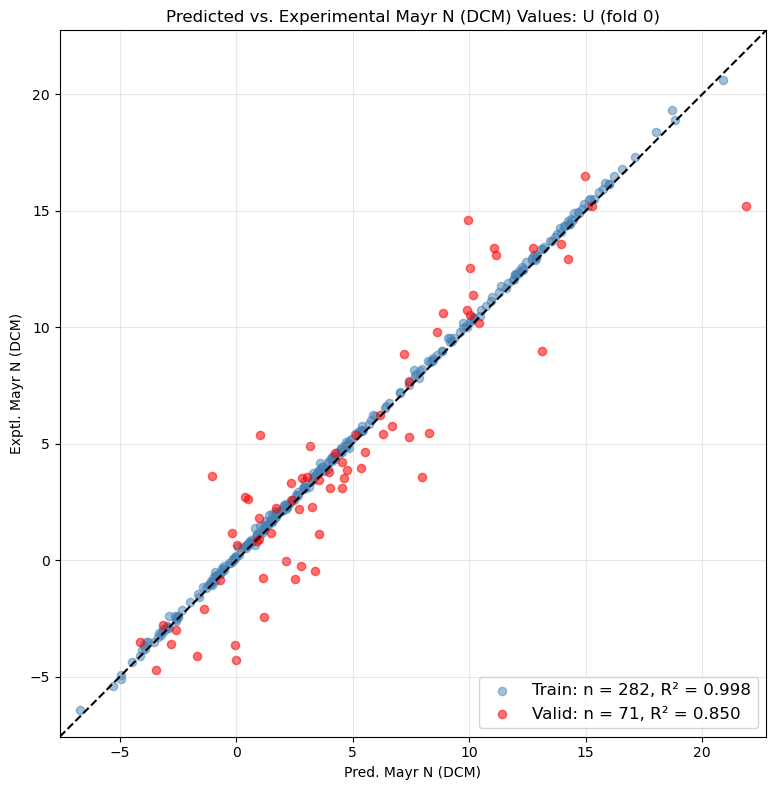

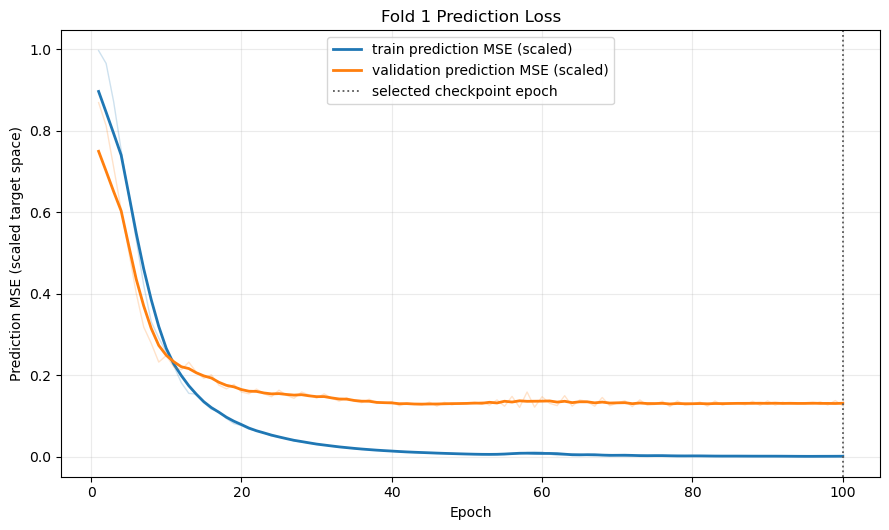

,condition,molecules,all_scaled_pass,all_raw_pass,max_raw_additivity_gap
0,U,353,True,True,0.000003


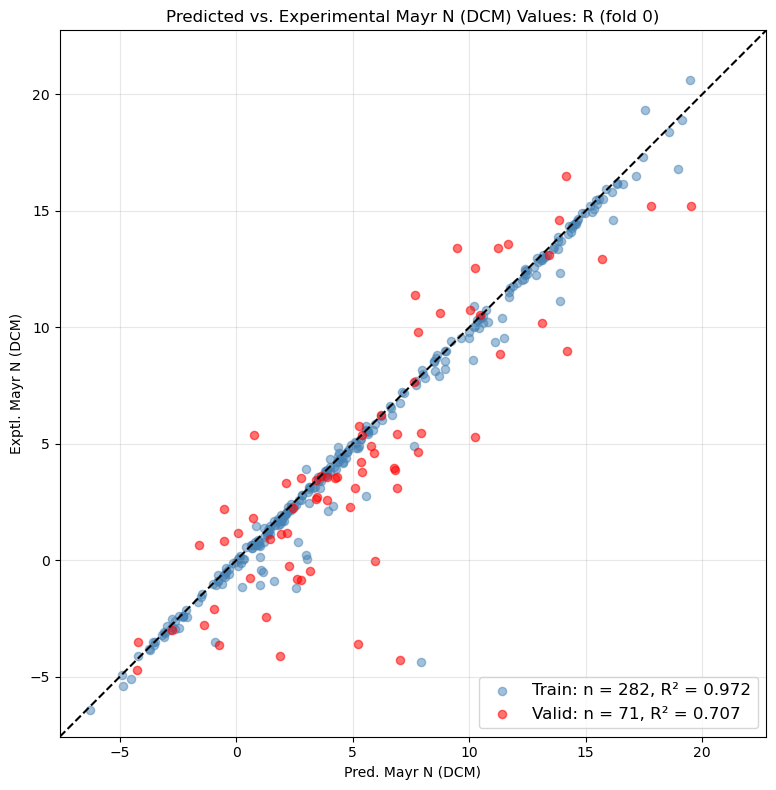

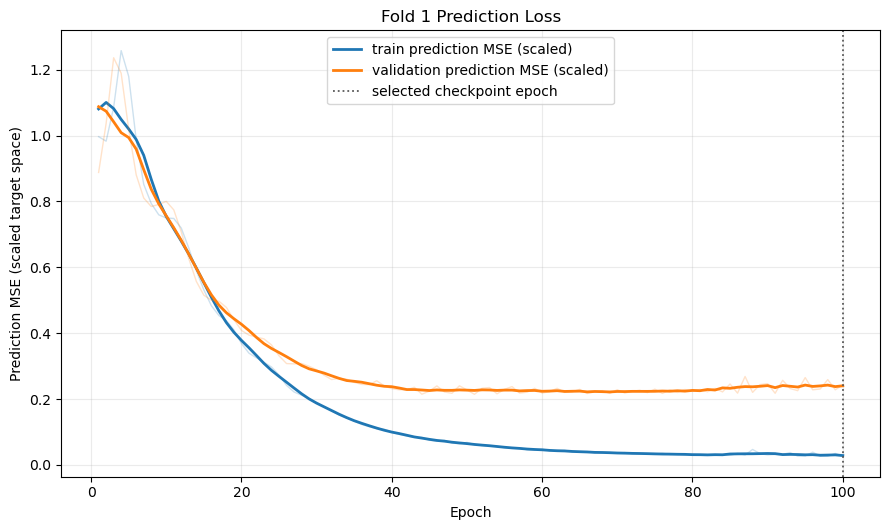

,condition,molecules,all_scaled_pass,all_raw_pass,max_raw_additivity_gap
0,R,353,True,True,0.000002


,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw,condition
0,train,282,0.236775,0.211946,0.998433,0.999632,U
1,validation,71,2.113676,1.559752,0.849576,0.853733,U
2,train,282,0.992684,0.384299,0.972463,0.975282,R
3,validation,71,2.949902,2.160239,0.707007,0.750506,R


In [11]:
TARGET_LABEL = "Mayr N (DCM)"
TARGET_UNITS = "Mayr N units"
from xai_chem.plotting import (
    plot_train_validation_yy, plot_prediction_loss_curves, save_publication_figure,
)
summary_rows = []
additivity_passed = {}
# U and R use identical axis limits; colours always identify train vs validation.
all_predictions = pd.concat([result.predictions for result in completed.values()])
span = all_predictions[["target_raw", "prediction_raw"]].to_numpy()
padding = 0.03 * max(float(span.max() - span.min()), 1.0)
limits = (float(span.min() - padding), float(span.max() + padding))
for label, result in completed.items():
    figure, scores = plot_train_validation_yy(
        result, run_name=label, limits=limits, target_label=TARGET_LABEL,
    )
    save_publication_figure(figure, run_root / "vis" / f"{label}_yy.png")
    display(figure); plt.close(figure)
    summary_rows.append(scores.assign(condition=label))
    figure = plot_prediction_loss_curves(result)
    save_publication_figure(figure, run_root / "vis" / f"{label}_learning.png")
    display(figure); plt.close(figure)
    audit = check_additivity(result.predictions, result.atom_contributions)
    additivity_passed[label] = bool(audit["scaled_pass"].all() and audit["raw_pass"].all())
    if not additivity_passed[label]:
        raise ValueError(f"Additivity failed for {label}")
    display(pd.DataFrame([{"condition": label, "molecules": len(audit),
        "all_scaled_pass": bool(audit["scaled_pass"].all()), "all_raw_pass": bool(audit["raw_pass"].all()),
        "max_raw_additivity_gap": float(audit["additivity_residual_raw_recomputed"].abs().max())}]))
summary = pd.concat(summary_rows, ignore_index=True)
display(summary)
summary.to_csv(run_root / "prediction_metrics.csv", index=False)


## 10. Reconstruct the same validation MMPs for U and R

Select up to three pairs by largest changed region, breaking ties by pair ID,
without inspecting fidelity. Fit the same seven RDKit atom descriptors on each
changed region. Display matched U/R in-sample fits and physical-feature totals.


In [12]:
from xai_chem.reconstruction import fit_pair
descriptors = rdkit_atom_descriptors(frame)
selected_pairs = mmp[validation_pairs].sort_values(["diff_total_count", "pair_id"], ascending=[False, True]).head(3)
display(selected_pairs[["pair_id", "i_id", "j_id", "diff_total_count"]])
atom_tables, fitted_pairs, fits = {}, {}, []
for label, result in completed.items():
    teacher = result.atom_contributions.rename(columns={"source_row_index": "graph_id", "smiles_atom_index": "atom_idx", "atom_contribution_raw": "atom_contribution"})
    atom_table = descriptors.merge(teacher[["graph_id", "atom_idx", "atom_contribution"]], on=["graph_id", "atom_idx"], validate="one_to_one")
    atom_tables[label] = atom_table
    for pair in selected_pairs.itertuples(index=False):
        context = f"{label}_pair_{pair.pair_id}"
        pieces = []
        for graph_id, indices in [(pair.i_id, json.loads(pair.diff_i_json)), (pair.j_id, json.loads(pair.diff_j_json))]:
            pieces.append(atom_table[atom_table["graph_id"].eq(graph_id) & atom_table["atom_idx"].isin(indices)].assign(context_id=context))
        inputs = pd.concat(pieces, ignore_index=True)
        key = pd.Series({"context_id": context, "pair_id": pair.pair_id,
                         "molecule_a": frame.iloc[pair.i_id]["cid"], "molecule_b": frame.iloc[pair.j_id]["cid"]})
        fitted = fit_pair(key, inputs, alpha=1.0, features=RDKit_DESCRIPTORS)
        display(fitted.metrics.assign(condition=label, pair_id=pair.pair_id))
        display(fitted.concept_totals)
        fitted.atoms.to_csv(run_root / f"{label}_pair_{pair.pair_id}_atom_reconstruction.csv", index=False)
        fits.append(fitted.metrics.assign(condition=label, pair_id=pair.pair_id))
        fitted_pairs[(label, pair.pair_id)] = fitted
reconstruction = pd.concat(fits, ignore_index=True)
reconstruction.to_csv(run_root / "descriptor_reconstruction.csv", index=False)


,pair_id,i_id,j_id,diff_total_count
164,180,234,268,11
193,211,172,214,9
199,217,214,224,8


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows,condition
0,U_pair_180,180,A+B diff-region atoms,11,0.946365,0.046975,0.036842,0.973365,0.954545,NaN,NaN,ridge,1.0,none,11,11,U
1,U_pair_180,180,endpoint A atoms,6,0.908772,0.058005,0.050780,0.957924,0.942857,NaN,NaN,ridge,1.0,none,11,11,U
2,U_pair_180,180,endpoint B atoms,5,0.981117,0.028587,0.020115,0.999392,1.000000,NaN,NaN,ridge,1.0,none,11,11,U
3,U_pair_180,180,B-A fragment sum,1,NaN,0.201152,0.201152,NaN,NaN,0.002801,-0.198351,ridge,1.0,none,11,11,U


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,2.402297e+00,-4.003828e-01
1,A,gasteiger_charge,-2.709006e-02,5.418012e-02
2,A,gasteiger_charge_square,-1.519231e-02,3.038463e-02
3,A,crippen_logp,-2.089301e-02,4.178602e-02
4,A,crippen_molar_refractivity,-2.089301e-02,4.178602e-02
5,A,tpsa_A2,0.000000e+00,0.000000e+00
6,A,atomic_mass,-4.685226e-44,7.808710e-45
7,A,total_hydrogens,-1.694770e-02,3.389540e-02
8,B,shared atom bias,2.001914e+00,-4.003828e-01
9,B,gasteiger_charge,2.709006e-02,5.418012e-02


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows,condition
0,U_pair_211,211,A+B diff-region atoms,9,0.718524,0.234689,0.167065,0.863884,0.783333,NaN,NaN,ridge,1.0,none,9,9,U
1,U_pair_211,211,endpoint A atoms,4,0.425553,0.221568,0.187949,0.962439,1.000000,NaN,NaN,ridge,1.0,none,9,9,U
2,U_pair_211,211,endpoint B atoms,5,-1.226161,0.244679,0.150359,0.629781,0.300000,NaN,NaN,ridge,1.0,none,9,9,U
3,U_pair_211,211,B-A fragment sum,1,NaN,1.503589,1.503589,NaN,NaN,4.000358,2.496769,ridge,1.0,none,9,9,U


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,2.483778,0.620944
1,A,gasteiger_charge,-0.041517,0.083033
2,A,gasteiger_charge_square,0.025127,-0.050254
3,A,crippen_logp,-0.082521,0.165042
4,A,crippen_molar_refractivity,-0.643972,1.287943
5,A,tpsa_A2,-0.023232,0.046463
6,A,atomic_mass,-0.023232,0.046463
7,A,total_hydrogens,-0.148567,0.297133
8,B,shared atom bias,3.104722,0.620944
9,B,gasteiger_charge,0.041517,0.083033


...

,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,-1.551800e+00,2.586333e-01
1,A,gasteiger_charge,-1.979647e-02,3.959293e-02
2,A,gasteiger_charge_square,3.097004e-03,-6.194009e-03
3,A,crippen_logp,1.276569e-02,-2.553138e-02
4,A,crippen_molar_refractivity,1.276569e-02,-2.553138e-02
5,A,tpsa_A2,0.000000e+00,0.000000e+00
6,A,atomic_mass,2.694139e-44,-4.490232e-45
7,A,total_hydrogens,-2.761515e-02,5.523030e-02
8,B,shared atom bias,-1.293167e+00,2.586333e-01
9,B,gasteiger_charge,1.979647e-02,3.959293e-02


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows,condition
0,R_pair_211,211,A+B diff-region atoms,9,0.606768,0.318089,0.237606,0.784676,0.816667,NaN,NaN,ridge,1.0,none,9,9,R
1,R_pair_211,211,endpoint A atoms,4,0.045171,0.402164,0.321304,0.613798,1.000000,NaN,NaN,ridge,1.0,none,9,9,R
2,R_pair_211,211,endpoint B atoms,5,0.635286,0.229645,0.170648,0.921951,0.900000,NaN,NaN,ridge,1.0,none,9,9,R
3,R_pair_211,211,B-A fragment sum,1,NaN,1.635605,1.635605,NaN,NaN,3.022067,1.386462,ridge,1.0,none,9,9,R


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,0.679364,0.169841
1,A,gasteiger_charge,0.002281,-0.004561
2,A,gasteiger_charge_square,-0.071673,0.143345
3,A,crippen_logp,-0.143700,0.287399
4,A,crippen_molar_refractivity,-0.718363,1.436726
5,A,tpsa_A2,0.079737,-0.159475
6,A,atomic_mass,0.079737,-0.159475
7,A,total_hydrogens,0.163669,-0.327338
8,B,shared atom bias,0.849205,0.169841
9,B,gasteiger_charge,-0.002281,-0.004561


,context_id,pair_id,level,n,r2,rmse,mae,pearson_r,spearman_r,observed_delta,predicted_delta,model_kind,alpha,augmentation_method,n_original_atoms,n_training_rows,condition
0,R_pair_217,217,A+B diff-region atoms,8,0.759515,0.164444,0.123206,0.877661,0.857143,NaN,NaN,ridge,1.0,none,8,8,R
1,R_pair_217,217,endpoint A atoms,5,0.801170,0.169559,0.120812,0.937428,0.900000,NaN,NaN,ridge,1.0,none,8,8,R
2,R_pair_217,217,endpoint B atoms,3,0.259369,0.155544,0.127195,0.911563,1.000000,NaN,NaN,ridge,1.0,none,8,8,R
3,R_pair_217,217,B-A fragment sum,1,NaN,0.763170,0.763170,NaN,NaN,-1.524304,-0.761134,ridge,1.0,none,8,8,R


,endpoint,concept,contribution,B_minus_A
0,A,shared atom bias,1.891457,-0.756583
1,A,gasteiger_charge,0.021357,-0.042713
2,A,gasteiger_charge_square,-0.188774,0.377547
3,A,crippen_logp,0.173491,-0.346981
4,A,crippen_molar_refractivity,0.171088,-0.342176
5,A,tpsa_A2,-0.028838,0.057677
6,A,atomic_mass,-0.028838,0.057677
7,A,total_hydrogens,-0.117209,0.234418
8,B,shared atom bias,1.134874,-0.756583
9,B,gasteiger_charge,-0.021357,-0.042713


## 11. Inspect raw ACs and reconstruction

Use one shared symmetric scale across both models and all displayed molecules.
Raw ACs are unchanged. Keep atom numbers, predictions, observations, errors,
separate affine baseline, colorbar, saturation audit, and atom-value tables in
Mayr N units. These maps follow the existing project renderer.


{'shared_raw_ac_symmetric_limit': 1.509390354156494, 'raw_ac_units': 'Mayr N units'}


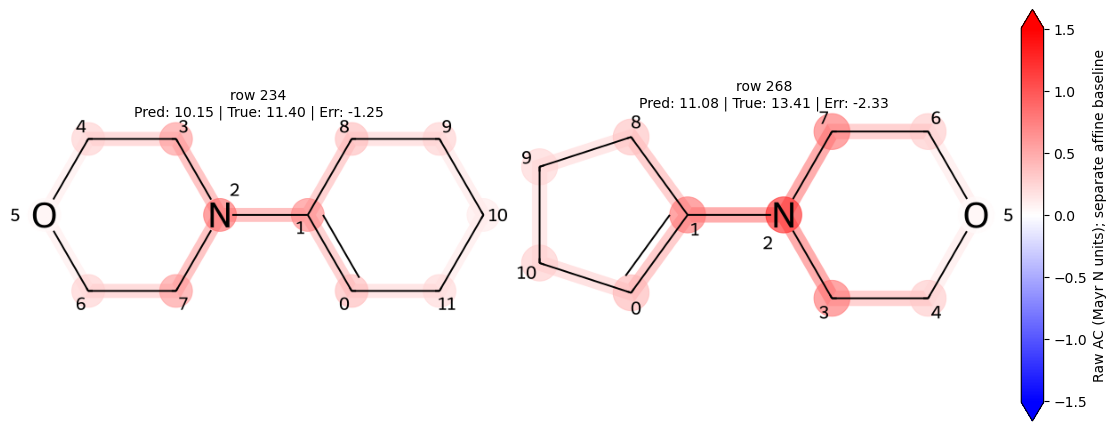

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,234,,validation,C1=C(N2CCOCC2)CCCC1,11.40,10.152861,-1.247139,5.219574,4.933286,0.000000e+00,0,0.0
1,268,,validation,C1=C(N2CCOCC2)CCC1,13.41,11.082939,-2.327061,5.219574,5.863365,-9.536743e-07,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,234,0,C,0.419728,0.419728
1,molecule,234,1,C,0.730098,0.730098
2,molecule,234,2,N,0.878433,0.878433
3,molecule,234,3,C,0.620686,0.620686
4,molecule,234,4,C,0.284889,0.284889
5,molecule,234,5,O,0.042997,0.042997
6,molecule,234,6,C,0.284889,0.284889
7,molecule,234,7,C,0.620686,0.620686
8,molecule,234,8,C,0.409708,0.409708
9,molecule,234,9,C,0.284834,0.284834


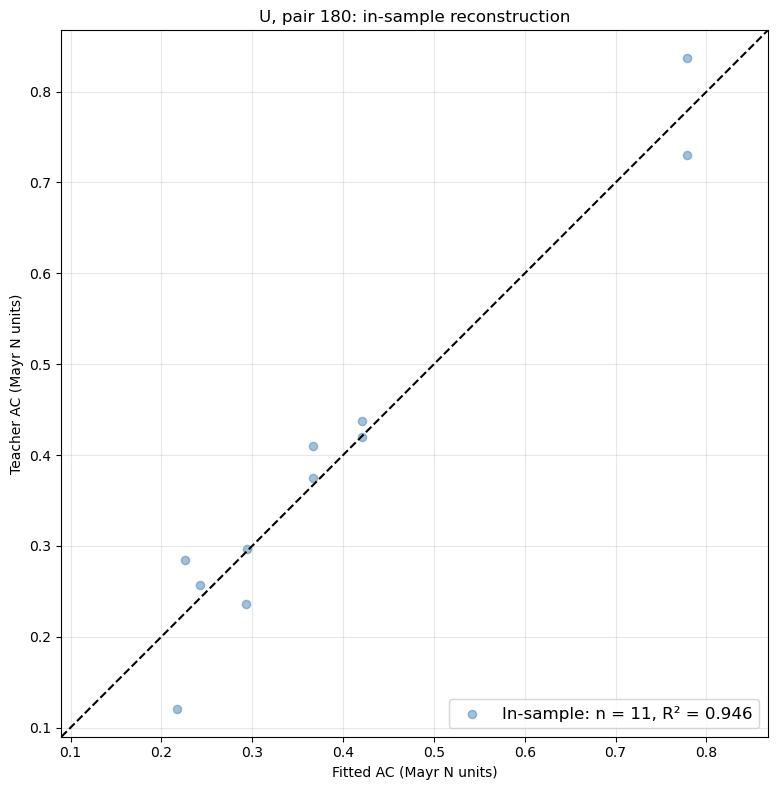

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,11,0.046975,0.036842,0.946365,0.947439


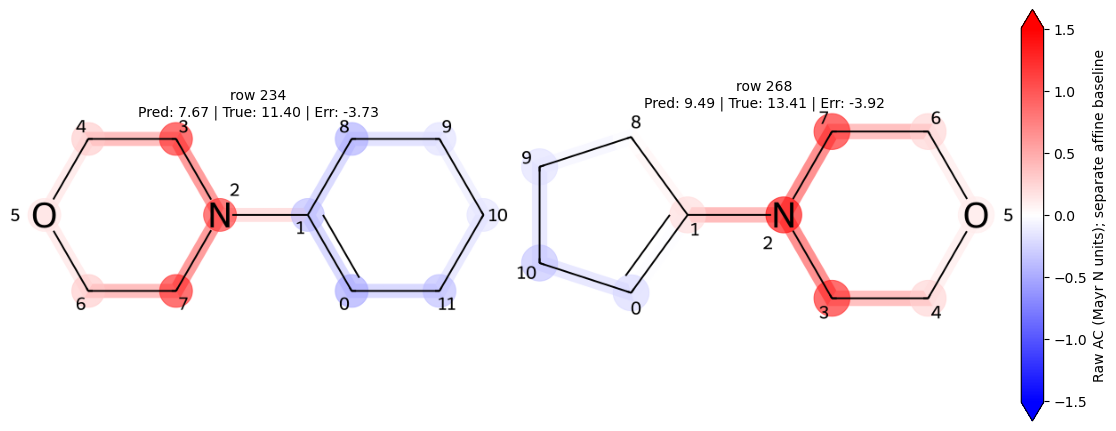

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,234,,validation,C1=C(N2CCOCC2)CCCC1,11.40,7.670958,-3.729042,5.219574,2.451383,0.0,0,0.0
1,268,,validation,C1=C(N2CCOCC2)CCC1,13.41,9.492536,-3.917464,5.219574,4.272961,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,234,0,C,-0.549596,0.549596
1,molecule,234,1,C,-0.408166,0.408166
2,molecule,234,2,N,1.229325,1.229325
3,molecule,234,3,C,1.329867,1.329867
4,molecule,234,4,C,0.325642,0.325642
5,molecule,234,5,O,0.162536,0.162536
6,molecule,234,6,C,0.325642,0.325642
7,molecule,234,7,C,1.329867,1.329867
8,molecule,234,8,C,-0.517955,0.517955
9,molecule,234,9,C,-0.199416,0.199416


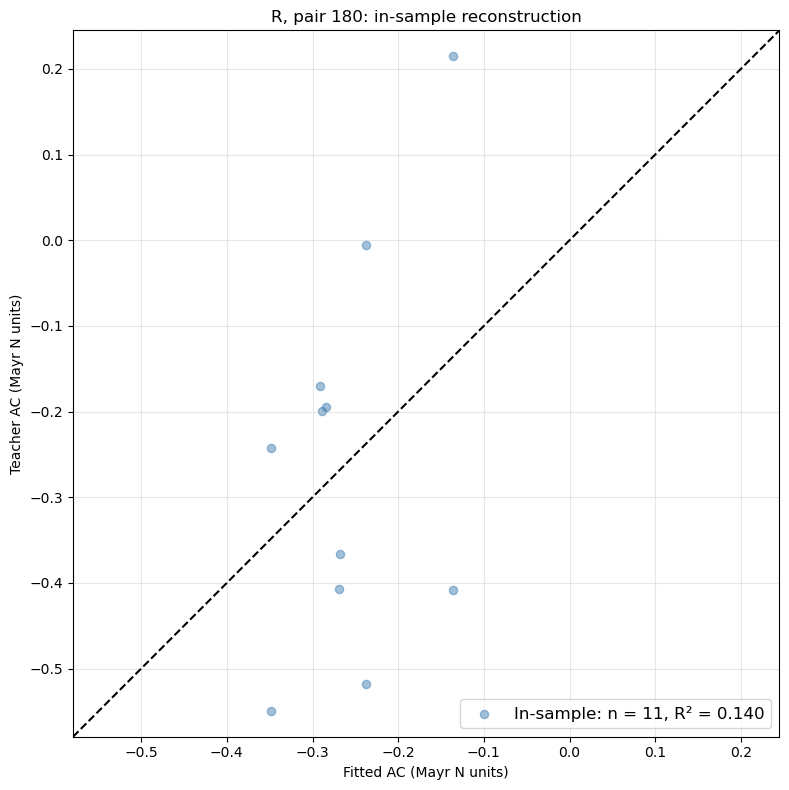

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,11,0.200113,0.179878,0.139856,0.144308


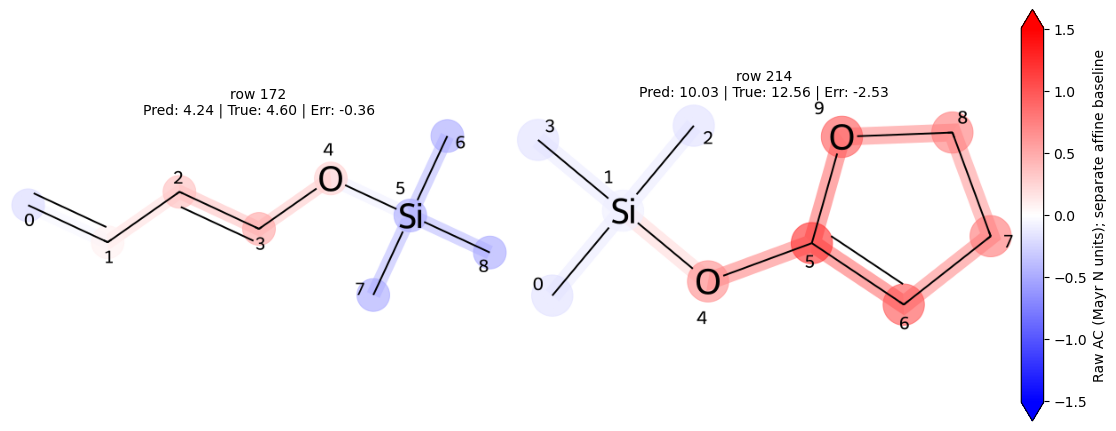

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,172,,validation,C=C/C=C/O[Si](C)(C)C,4.60,4.236161,-0.363839,5.219574,-0.983414,0.000000e+00,0,0.0
1,214,,validation,C[Si](C)(C)OC1=CCCO1,12.56,10.030553,-2.529448,5.219574,4.810978,9.536743e-07,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,172,0,C,-0.224101,0.224101
1,molecule,172,1,C,0.089018,0.089018
2,molecule,172,2,C,0.395046,0.395046
3,molecule,172,3,C,0.534108,0.534108
4,molecule,172,4,O,0.273887,0.273887
5,molecule,172,5,Si,-0.504575,0.504575
6,molecule,172,6,C,-0.515599,0.515599
7,molecule,172,7,C,-0.515599,0.515599
8,molecule,172,8,C,-0.515599,0.515599
9,molecule,214,0,C,-0.184626,0.184626


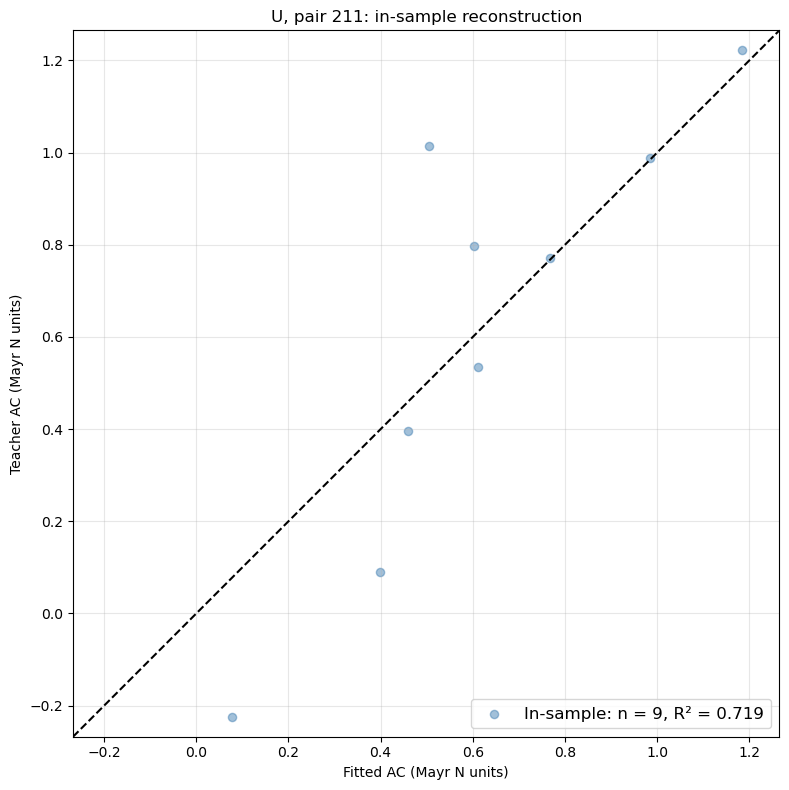

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,9,0.234689,0.167065,0.718524,0.746295


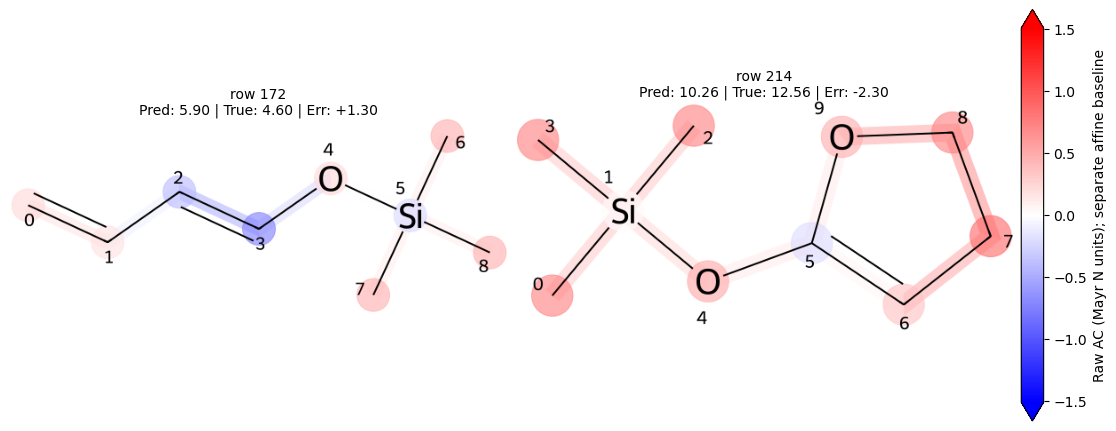

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,172,,validation,C=C/C=C/O[Si](C)(C)C,4.60,5.904854,1.304854,5.219574,0.685279,0.0,0,0.0
1,214,,validation,C[Si](C)(C)OC1=CCCO1,12.56,10.264000,-2.296000,5.219574,5.044426,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,172,0,C,0.233259,0.233259
1,molecule,172,1,C,0.180607,0.180607
2,molecule,172,2,C,-0.412359,0.412359
3,molecule,172,3,C,-0.748256,0.748256
4,molecule,172,4,O,0.228427,0.228427
5,molecule,172,5,Si,-0.231670,0.231670
6,molecule,172,6,C,0.478424,0.478424
7,molecule,172,7,C,0.478424,0.478424
8,molecule,172,8,C,0.478424,0.478424
9,molecule,214,0,C,0.743790,0.743790


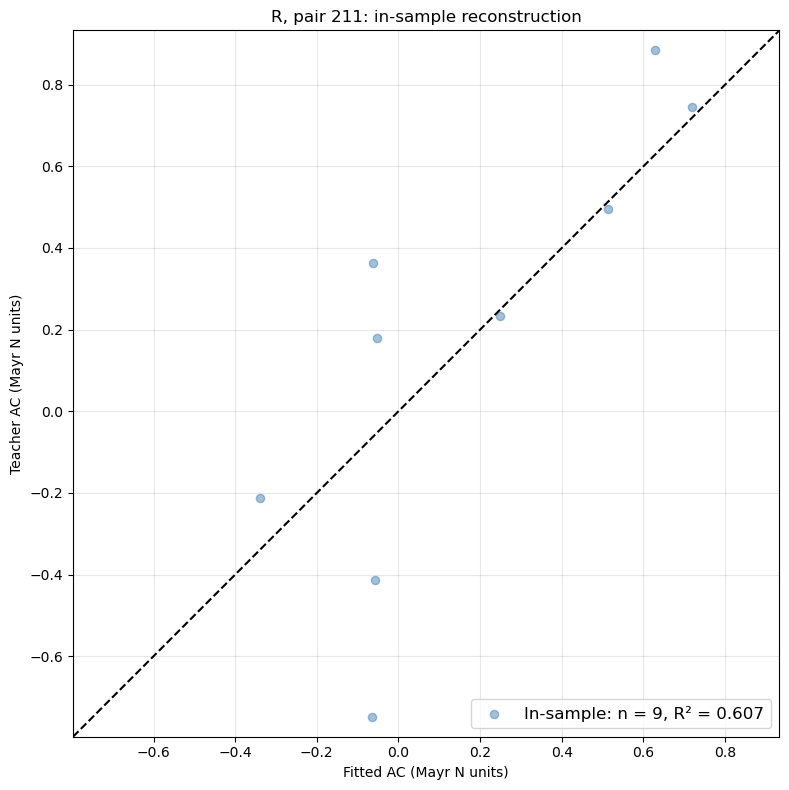

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,9,0.318089,0.237606,0.606768,0.615717


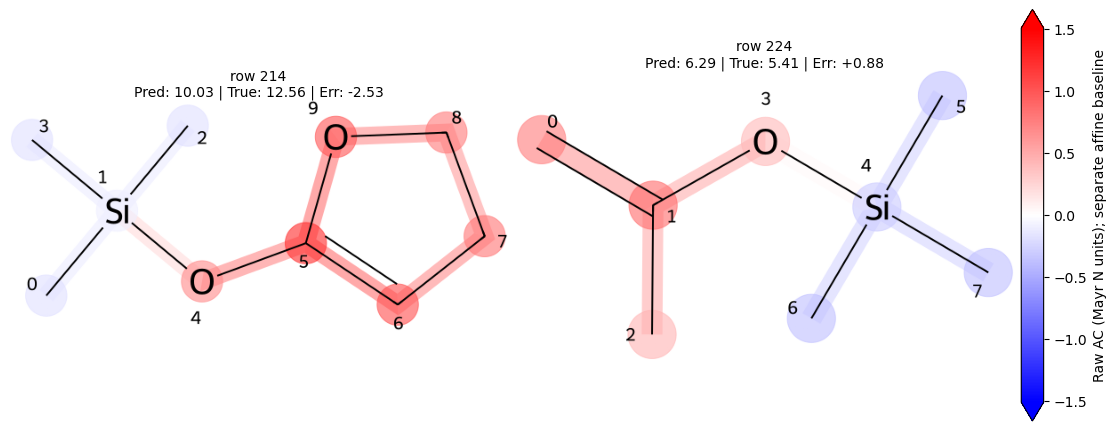

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,214,,validation,C[Si](C)(C)OC1=CCCO1,12.56,10.030553,-2.529448,5.219574,4.810978,9.536743e-07,0,0.0
1,224,,validation,C=C(C)O[Si](C)(C)C,5.41,6.286980,0.876980,5.219574,1.067406,0.000000e+00,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,214,0,C,-0.184626,0.184626
1,molecule,214,1,Si,-0.102420,0.102420
2,molecule,214,2,C,-0.184626,0.184626
3,molecule,214,3,C,-0.184626,0.184626
4,molecule,214,4,O,0.672846,0.672846
5,molecule,214,5,C,1.221968,1.221968
6,molecule,214,6,C,1.014506,1.014506
7,molecule,214,7,C,0.797297,0.797297
8,molecule,214,8,C,0.771460,0.771460
9,molecule,214,9,O,0.989199,0.989199


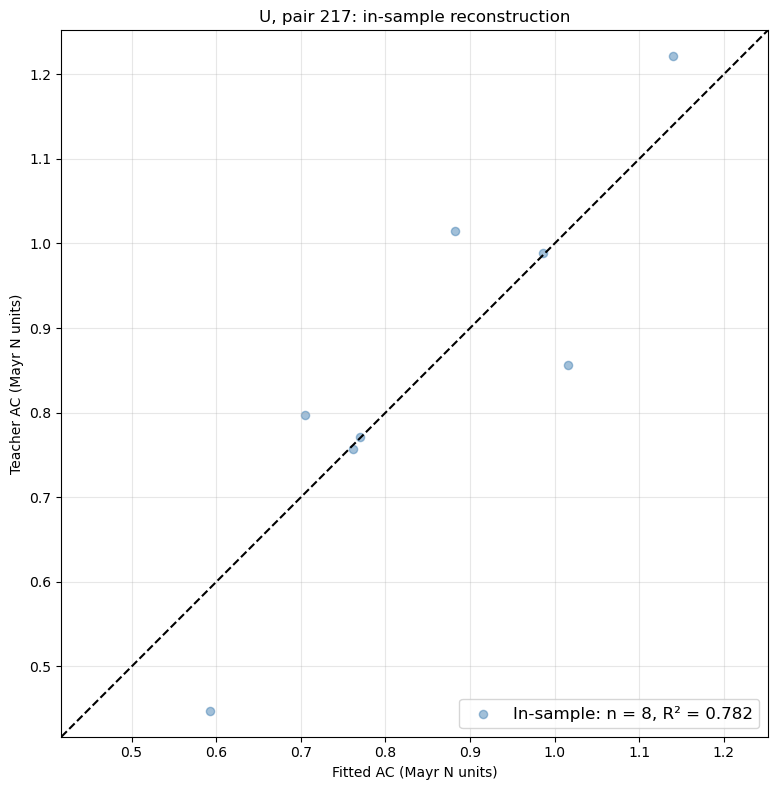

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,8,0.099617,0.077478,0.782185,0.790451


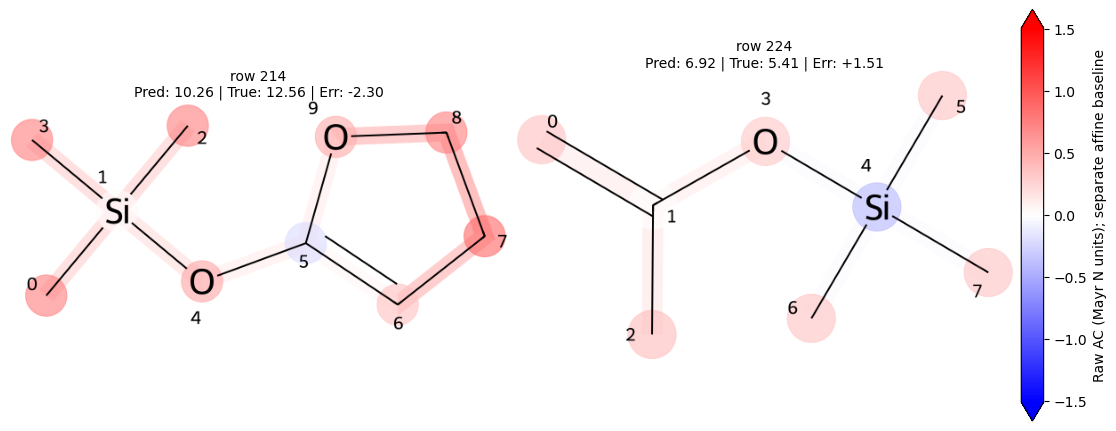

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,214,,validation,C[Si](C)(C)OC1=CCCO1,12.56,10.264000,-2.296000,5.219574,5.044426,0.0,0,0.0
1,224,,validation,C=C(C)O[Si](C)(C)C,5.41,6.916686,1.506686,5.219574,1.697112,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,214,0,C,0.743790,0.743790
1,molecule,214,1,Si,0.025512,0.025512
2,molecule,214,2,C,0.743790,0.743790
3,molecule,214,3,C,0.743790,0.743790
4,molecule,214,4,O,0.512226,0.512226
5,molecule,214,5,C,-0.212016,0.212016
6,molecule,214,6,C,0.363355,0.363355
7,molecule,214,7,C,0.884128,0.884128
8,molecule,214,8,C,0.744678,0.744678
9,molecule,214,9,O,0.495173,0.495173


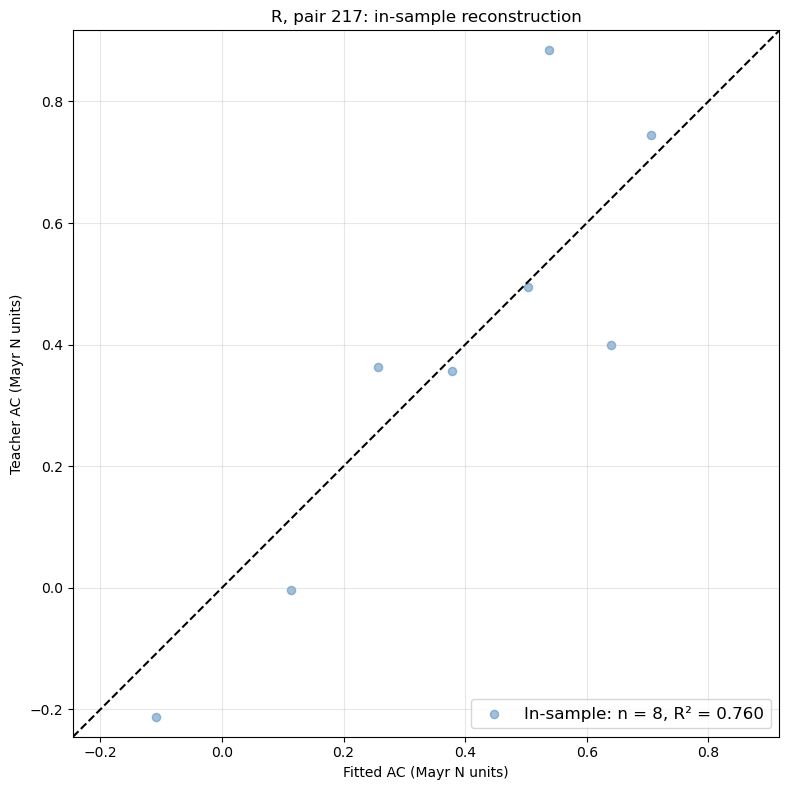

,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,8,0.164444,0.123206,0.759515,0.770289


In [13]:
from xai_chem.plotting import plot_atom_contribution_grid, plot_reconstruction_yy

selected_graph_ids = set(selected_pairs["i_id"]) | set(selected_pairs["j_id"])
shared_limit = max(float(table.loc[table["graph_id"].isin(selected_graph_ids), "atom_contribution"].abs().max()) for table in atom_tables.values())
print({"shared_raw_ac_symmetric_limit": shared_limit, "raw_ac_units": TARGET_UNITS})
for pair in selected_pairs.itertuples(index=False):
    for label, result in completed.items():
        fitted = fitted_pairs[(label, pair.pair_id)]
        figure, molecule_audit, atom_audit = plot_atom_contribution_grid(
            result, source_rows=[pair.i_id, pair.j_id], symmetric_limit=shared_limit,
            draw_atom_indices=True, contribution_label=f"Raw AC ({TARGET_UNITS}); separate affine baseline",
        )
        save_publication_figure(figure, run_root / "vis" / f"{label}_pair_{pair.pair_id}_raw_ac.png")
        molecule_audit.to_csv(run_root / f"{label}_pair_{pair.pair_id}_map_audit.csv", index=False)
        atom_audit.to_csv(run_root / f"{label}_pair_{pair.pair_id}_raw_atom_values.csv", index=False)
        display(figure); plt.close(figure)
        display(molecule_audit)
        display(atom_audit)
        figure, scores = plot_reconstruction_yy(
            fitted.atoms["atom_contribution"], fitted.atoms["prediction"],
            unit_label=f"AC ({TARGET_UNITS})", title=f"{label}, pair {pair.pair_id}: in-sample reconstruction",
        )
        save_publication_figure(figure, run_root / "vis" / f"{label}_pair_{pair.pair_id}_reconstruction_yy.png")
        display(figure); plt.close(figure)
        display(scores)


Raw ACs decompose the model prediction. The pairwise fit uses only changed-region atoms and is in-sample; it does not validate a causal or transferable physicochemical attribution.

## 12. WISP: matched train/train and validation/validation pairs

Compute the official five metrics using i-minus-j differences. Divide atom-sum
gaps by one model-wide atom population SD (ddof=0), shared across its two splits.
Do not center or transform raw AC maps. Squared Pearson r is distinct from
regression R². Whole/prediction correlation is largely guaranteed by additivity;
variable-region agreement, constant-region dispersion, and direction accuracy
are the informative locality checks. Report raw constant-gap SD alongside the
normalized metric because U/R attribution scales can differ.

Definitions: [WISP](https://github.com/kerjans/ml-XAI),
[Janssen et al.](https://doi.org/10.1039/D5DD00398A).
These are explanation diagnostics, not comparisons against a separate WISP model.

In [14]:
from xai_chem.wisp import build_wisp_pair_table, summarize_official_wisp_metrics

wisp_rows = []
for label, result in completed.items():
    for split in ("train", "validation"):
        pairs, atom_std = build_wisp_pair_table(mmp, result.predictions, result.atom_contributions, split=split)
        pairs.to_csv(run_root / f"{label}_{split}_wisp_pairs.csv", index=False)
        metrics = summarize_official_wisp_metrics(pairs)
        wisp_rows.append({"condition": label, "split": split,
                          "atom_population_std_raw": atom_std,
                          "constant_gap_std_raw": float(np.std(pairs.constant_attribution_gap_raw, ddof=0)),
                          "max_pair_additivity_gap_raw": float(pairs.additivity_gap_raw.abs().max()), **metrics})
wisp_summary = pd.DataFrame(wisp_rows)
display(wisp_summary)
wisp_summary.to_csv(run_root / "wisp_metrics.csv", index=False)
for split in ("train", "validation"):
    u_pairs = pd.read_csv(run_root / f"U_{split}_wisp_pairs.csv")
    r_pairs = pd.read_csv(run_root / f"R_{split}_wisp_pairs.csv")
    if not u_pairs[["pair_id", "i_id", "j_id"]].equals(r_pairs[["pair_id", "i_id", "j_id"]]):
        raise ValueError("U/R WISP pair populations differ")

,condition,split,atom_population_std_raw,constant_gap_std_raw,max_pair_additivity_gap_raw,n_pairs_evaluated,whole_to_prediction_pearson_r_squared,variable_to_prediction_pearson_r_squared,whole_to_observed_pearson_r_squared,constant_attribution_gap_std,variable_to_prediction_direction_accuracy
0,U,train,0.653069,3.263965,2.644956e-06,379,1.0,0.887084,0.999649,4.997885,0.844327
1,U,validation,0.653069,1.996931,6.556511e-07,17,1.0,0.671431,0.789583,3.057763,0.823529
2,R,train,0.812243,0.940597,2.916902e-06,379,1.0,0.981280,0.884121,1.158025,0.941953
3,R,validation,0.812243,1.585509,1.862645e-06,17,1.0,0.747838,0.650572,1.952014,0.823529


## 13. Acceptance record


In [15]:
training_decreased = {
    label: bool(result.history.iloc[-1]["optimization_prediction_mse_scaled"] < result.history.iloc[0]["optimization_prediction_mse_scaled"])
    for label, result in completed.items()
}
record = {"dataset": "BNNLab_Mayr_GAS_SET_DCM", "molecules": len(frame), "target": "mayr_N",
          "target_units": "Mayr N units", "fold": 0, "seed": SEED, "epochs": EPOCHS,
          "training_prediction_loss_decreased": training_decreased,
          "all_models_additive": all(additivity_passed.values()),
          "all_four_training_constraints_lower": bool((ratios < 1).all()),
          "training_constraint_ratios_R_div_U": {key: float(value) for key, value in ratios.items()},
          "raw_ac_symmetric_limit": shared_limit,
          "descriptor_pairs_per_model": len(selected_pairs), "wisp_scope": "within_split_pairs", "wisp_metrics": wisp_summary.to_dict("records"), "ridge_alpha": 1.0,
          "descriptor_contract": list(RDKit_DESCRIPTORS), "reconstruction_scope": "in_sample_diff_region_atoms"}
print(json.dumps(record, indent=2))
(run_root / "acceptance.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n")
if not all(training_decreased.values()) or len(selected_pairs) < 1:
    raise ValueError("mayr_dcm acceptance condition was not met; inspect the measured results")


{
  "dataset": "BNNLab_Mayr_GAS_SET_DCM",
  "molecules": 353,
  "target": "mayr_N",
  "target_units": "Mayr N units",
  "fold": 0,
  "seed": 42,
  "epochs": 100,
  "training_prediction_loss_decreased": {
    "U": true,
    "R": true
  },
  "all_models_additive": true,
  "all_four_training_constraints_lower": true,
  "training_constraint_ratios_R_div_U": {
    "core": 0.10948649045124693,
    "difference": 0.559496381968153,
    "positive": 0.0001597220081530382,
    "consistency": 0.0005667560044313127
  },
  "raw_ac_symmetric_limit": 1.509390354156494,
  "descriptor_pairs_per_model": 3,
  "wisp_scope": "within_split_pairs",
  "wisp_metrics": [
    {
      "condition": "U",
      "split": "train",
      "atom_population_std_raw": 0.6530693489885993,
      "constant_gap_std_raw": 3.2639654197462016,
      "max_pair_additivity_gap_raw": 2.644956111907959e-06,
      "n_pairs_evaluated": 379,
      "whole_to_prediction_pearson_r_squared": 0.9999999999999891,
      "variable_to_prediction_p

The experiment establishes measured behavior for this split and settings only.
A lower regularization penalty is not evidence of physically correct ACs.
Ridge fidelity is in-sample reconstruction, not prediction on unseen atoms.
The supplied endpoint is preserved. Fragment positivity remains a model-design
assumption that needs endpoint-specific scrutiny.
